# 📉 BASELINE GARCH(1,1) — Prediksi Volatilitas Return Saham (t+1)
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### Tujuan
Menjawab **Reviewer 1, Komentar #2** dengan menambahkan pembanding ekonometrika klasik **GARCH(1,1)** (Bollerslev, 1986).

### Prinsip pembandingan (identik dengan XGBoost & LSTM)
| Aspek | Sumber / Pengaturan |
|---|---|
| Return | `Log_Return` dari `03_dataset/final/dataset_gabungan_X1X2Y.csv` (data yang sama) |
| Target | `Volatilitas_Target` (vol rolling 20 hari, t+1), **skala asli** |
| Tanggal uji & nilai aktual | `Date` + `Y_Aktual` dari `hasil_prediksi_xgboost.csv` → **test set identik** |
| Metrik | RMSE, MAE, MAPE, sMAPE, R², QLIKE (fungsi sama dgn notebook XGBoost) |
| Anti-leakage | Parameter GARCH hanya diestimasi dari data **≤ t** (expanding window, re-estimasi tiap 20 hari bursa) |

**Letak notebook:** `04_model/FIX/` · **Output:** `06_dokumen_tesis/tabel/` & `06_dokumen_tesis/gambar/model/`

## ⚙️ CELL 0 — Path Kanonik (sama dengan notebook lain)

In [1]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from arch import arch_model          # pip install arch
warnings.filterwarnings('ignore')

ROOT_HARDCODED = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                      r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

def cari_root():
    p = Path(os.getcwd())
    for _ in range(8):
        if (p / '03_dataset').exists():
            return p
        p = p.parent
    if ROOT_HARDCODED.exists():
        return ROOT_HARDCODED
    raise FileNotFoundError('ROOT proyek (folder berisi 03_dataset/) tidak ditemukan.')

ROOT       = cari_root()
DIR_FINAL  = ROOT / '03_dataset' / 'final'
DIR_TABEL  = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_TABEL, DIR_GAMBAR): d.mkdir(parents=True, exist_ok=True)

F_GABUNGAN = DIR_FINAL / 'dataset_gabungan_X1X2Y.csv'
F_PRED_XGB = DIR_TABEL / 'hasil_prediksi_xgboost.csv'
F_PRED_LSTM = DIR_TABEL / 'hasil_prediksi_lstm.csv'   # ← sesuaikan jika nama file LSTM berbeda

print(f'ROOT : {ROOT.resolve()}')
for f in (F_GABUNGAN, F_PRED_XGB, F_PRED_LSTM):
    print(f"  {'✅' if f.exists() else '❌'} {f.relative_to(ROOT)}")

ROOT : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
  ✅ 03_dataset\final\dataset_gabungan_X1X2Y.csv
  ✅ 06_dokumen_tesis\tabel\hasil_prediksi_xgboost.csv
  ✅ 06_dokumen_tesis\tabel\hasil_prediksi_lstm.csv


## ⚙️ CELL 1 — Konfigurasi

In [2]:
URUTAN_EMITEN = ['ADRO','ADMR','ITMG','PTBA','MEDC','AKRA','PGAS']
WINDOW      = 20     # window volatilitas rolling (sama dengan PREP_01)
REFIT_EVERY = 20     # re-estimasi parameter GARCH tiap 20 hari bursa
DIST        = 't'    # distribusi error: 't' (Student-t) atau 'normal'
SCALE       = 100.0  # return ×100 agar optimasi numerik arch stabil

## 📂 CELL 2 — Load Data (harga → log return & volatilitas yang SAMA dengan XGBoost/LSTM)

Kolom dideteksi otomatis (`Tanggal`/`Date`, `Kode_Emiten`/`Emiten`).
Tanggal & nilai aktual test set diambil langsung dari `hasil_prediksi_xgboost.csv`,
sehingga GARCH dievaluasi pada **hari yang persis sama** dengan XGBoost.

In [3]:
def pilih_kolom(df, kandidat, nama):
    for k in kandidat:
        if k in df.columns:
            return k
    raise KeyError(f"Kolom {nama} tidak ditemukan. Dicari: {kandidat}. Tersedia: {df.columns.tolist()}")

# ── 1. Dataset gabungan: Log_Return & Volatilitas_Target (skala asli) ──
gab = pd.read_csv(F_GABUNGAN)
K_TGL = pilih_kolom(gab, ['Tanggal', 'Date'], 'tanggal')
K_EMT = pilih_kolom(gab, ['Kode_Emiten', 'Emiten', 'Ticker'], 'emiten')
K_RET = pilih_kolom(gab, ['Log_Return'], 'log return')
K_TGT = pilih_kolom(gab, ['Volatilitas_Target'], 'target')

gab = gab.rename(columns={K_TGL: 'Date', K_EMT: 'Emiten', K_RET: 'r', K_TGT: 'target'})
gab['Date'] = pd.to_datetime(gab['Date']).dt.tz_localize(None).dt.normalize()
gab = gab.sort_values(['Emiten', 'Date']).reset_index(drop=True)
print(f'Dataset gabungan : {len(gab):,} baris | kolom dipakai: {K_TGL}, {K_EMT}, {K_RET}, {K_TGT}')

# ── 2. Test set XGBoost: tanggal uji + Y_Aktual + Y_Prediksi (skala asli) ──
def muat_prediksi(path, nama_model):
    if not path.exists():
        print(f'  ⚠️ {path.name} tidak ada → {nama_model} dilewati')
        return None
    p = pd.read_csv(path)
    p['Date'] = pd.to_datetime(p['Date']).dt.tz_localize(None).dt.normalize()
    return p.rename(columns={'Y_Aktual': f'Aktual_{nama_model}', 'Y_Prediksi': nama_model})

pred_xgb  = muat_prediksi(F_PRED_XGB, 'XGBoost')
pred_lstm = muat_prediksi(F_PRED_LSTM, 'LSTM')
if pred_xgb is None:
    raise FileNotFoundError('hasil_prediksi_xgboost.csv wajib ada → jalankan MODEL_xgboost_FIX_V3 dulu.')

# ── 3. Bentuk dict per emiten: series return lengkap + tanggal uji ──
dict_data, dict_test_dates = {}, {}
for e in URUTAN_EMITEN:
    d = gab[gab['Emiten'] == e].set_index('Date')[['r', 'target']]
    d = d[~d.index.duplicated(keep='last')]
    dict_data[e] = d
    tgl = pred_xgb.loc[pred_xgb['Emiten'] == e, 'Date']
    dict_test_dates[e] = pd.DatetimeIndex(tgl).intersection(d.dropna(subset=['target']).index)
    print(f'  {e}: {len(d):,} hari | uji {len(dict_test_dates[e])} hari '
          f'({dict_test_dates[e].min().date()} s.d. {dict_test_dates[e].max().date()})')

Dataset gabungan : 7,494 baris | kolom dipakai: Date, Emiten, Log_Return, Volatilitas_Target
  ADRO: 1,074 hari | uji 215 hari (2025-08-08 s.d. 2026-06-30)
  ADMR: 1,050 hari | uji 210 hari (2025-08-15 s.d. 2026-06-30)
  ITMG: 1,074 hari | uji 215 hari (2025-08-08 s.d. 2026-06-30)
  PTBA: 1,074 hari | uji 215 hari (2025-08-08 s.d. 2026-06-30)
  MEDC: 1,074 hari | uji 215 hari (2025-08-08 s.d. 2026-06-30)
  AKRA: 1,074 hari | uji 215 hari (2025-08-08 s.d. 2026-06-30)
  PGAS: 1,074 hari | uji 215 hari (2025-08-08 s.d. 2026-06-30)


## ✅ CELL 3 — Cek Konsistensi Data (WAJIB lolos sebelum lanjut)

1. `Log_Return` harus **skala asli** (bukan hasil MinMax 0–1).
2. Rumus volatilitas: rolling std 20 hari dari `Log_Return`, digeser ke t+1 → harus sama dengan `Volatilitas_Target`. Cell ini juga mendeteksi `ddof` (0 = `np.std`, 1 = pandas).
3. `Volatilitas_Target` di dataset gabungan harus sama dengan `Y_Aktual` di hasil XGBoost.

In [4]:
rows_cek, ddof_terdeteksi = [], []
for e in URUTAN_EMITEN:
    d = dict_data[e]
    r = d['r']
    # (1) skala return
    skala_ok = not (r.min() >= 0 and r.max() <= 1)
    # (2) rumus target: coba ddof=1 dan ddof=0
    err = {}
    for dd in (1, 0):
        rek = r.rolling(WINDOW).std(ddof=dd).shift(-1)
        m = rek.notna() & d['target'].notna()
        err[dd] = (rek[m] - d['target'][m]).abs().max()
    ddof_best = min(err, key=err.get)
    ddof_terdeteksi.append(ddof_best)
    # (3) target gabungan vs Y_Aktual XGBoost
    px = pred_xgb[pred_xgb['Emiten'] == e].set_index('Date')['Aktual_XGBoost']
    common = px.index.intersection(d.index)
    selisih_akt = (d.loc[common, 'target'] - px.loc[common]).abs().max()
    rows_cek.append({'Emiten': e, 'Return skala asli': skala_ok,
                     'ddof': ddof_best, 'Selisih rumus target': err[ddof_best],
                     'Selisih vs Y_Aktual XGB': selisih_akt})

cek = pd.DataFrame(rows_cek)
print(cek.to_string(index=False, float_format=lambda x: f'{x:.2e}'))

DDOF = max(set(ddof_terdeteksi), key=ddof_terdeteksi.count)
print(f'\n➡️ ddof dipakai: {DDOF}')
if not cek['Return skala asli'].all():
    print('❌ Log_Return terlihat sudah di-MinMax (0–1). Gunakan file return skala asli (technical_features.csv).')
if (cek['Selisih rumus target'] > 1e-6).any():
    print('⚠️ Rumus target tidak persis sama (window/ddof/sumber harga berbeda) → cek PREP_01. '
          'Evaluasi tetap memakai Y_Aktual XGBoost sehingga tetap sebanding.')
if (cek['Selisih vs Y_Aktual XGB'] > 1e-6).any():
    print('⚠️ Volatilitas_Target ≠ Y_Aktual XGBoost → cek tanggal (t vs t+1) atau inverse-transform.')
else:
    print('✅ Target & tanggal uji identik dengan XGBoost.')

Emiten  Return skala asli  ddof  Selisih rumus target  Selisih vs Y_Aktual XGB
  ADRO               True     1              3.71e-16                 1.04e-16
  ADMR               True     1              3.87e-16                 1.11e-16
  ITMG               True     1              2.19e-16                 1.04e-16
  PTBA               True     1              1.77e-16                 1.01e-16
  MEDC               True     1              1.04e-16                 1.04e-16
  AKRA               True     1              9.37e-17                 1.04e-16
  PGAS               True     1              1.34e-16                 1.04e-16

➡️ ddof dipakai: 1
✅ Target & tanggal uji identik dengan XGBoost.


## 📐 CELL 4 — Model GARCH(1,1) & Konversi ke Target Rolling 20 Hari

$$r_t = \mu + \varepsilon_t,\quad \varepsilon_t = \sigma_t z_t,\quad z_t \sim t_\nu,\qquad
\sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$$

GARCH memprediksi varians return **harian** $\hat\sigma^2_{t+1}$, sedangkan target adalah std **sampel 20 hari**.
Pada hari $t$, 19 return $x_1,\dots,x_{19}$ sudah diketahui; hanya $r_{t+1} \sim (\mu, \hat\sigma^2_{t+1})$ yang belum.
Prediksi = akar nilai harapan varians sampel (untuk $n = 20$, pembagi $n-\text{ddof}$):

$$E[S^2] = \frac{1}{n-\text{ddof}}\left[\sum_{k=1}^{19} x_k^2 + \mu^2 + \hat\sigma^2_{t+1} - n\left(\frac{\sum x_k + \mu}{n}\right)^2 - \frac{\hat\sigma^2_{t+1}}{n}\right],
\qquad \hat\sigma^{(20)}_{t+1} = \sqrt{E[S^2]}$$

In [5]:
def expected_rolling_std(r_known, m, s2, ddof=1):
    n = len(r_known) + 1
    sx, sx2 = r_known.sum(), (r_known ** 2).sum()
    e_sum_sq  = sx2 + m**2 + s2
    e_mean_sq = ((sx + m) / n) ** 2 + s2 / n**2
    var = (e_sum_sq - n * e_mean_sq) / (n - ddof)
    return np.sqrt(max(var, 1e-12))


def predict_garch(d, test_dates):
    r_raw = d['r'].dropna()
    r = r_raw * SCALE
    test_pos = [r.index.get_loc(t) for t in test_dates]
    preds, sig_daily, params_log = [], [], []

    for b in range(0, len(test_pos), REFIT_EVERY):
        blok = test_pos[b:b + REFIT_EVERY]
        t0 = r.index[blok[0]]
        am = arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist=DIST)
        # last_obs eksklusif → estimasi memakai data s.d. t0 (inklusif), TANPA data masa depan
        last_obs = r.index[blok[0] + 1] if blok[0] + 1 < len(r) else None
        res = am.fit(last_obs=last_obs, disp='off', show_warning=False)
        params_log.append(res.params.rename(t0.date()))

        var_next = res.forecast(start=t0, horizon=1, reindex=False).variance['h.1']
        mu = res.params['mu'] / SCALE
        for p in blok:
            t = r.index[p]
            s2 = var_next.loc[t] / SCALE**2
            r_known = r_raw.iloc[p - (WINDOW - 2): p + 1].values   # r_{t-18..t}
            preds.append(expected_rolling_std(r_known, mu, s2, DDOF))
            sig_daily.append(np.sqrt(s2))
    return np.array(preds), np.array(sig_daily), pd.DataFrame(params_log)

print('✅ Fungsi GARCH siap.')

✅ Fungsi GARCH siap.


## 🔧 CELL 5 — Fungsi Evaluasi (identik dengan notebook XGBoost) & Uji Diebold–Mariano

In [6]:
def _mape(y, p, eps=1e-8):
    y=np.asarray(y,float); p=np.asarray(p,float); m=np.abs(y)>eps
    return np.nan if m.sum()==0 else float(np.mean(np.abs((y[m]-p[m])/y[m]))*100)

def _smape(y, p, eps=1e-8):
    y=np.asarray(y,float); p=np.asarray(p,float); d=np.abs(y)+np.abs(p); m=d>eps
    return np.nan if m.sum()==0 else float(np.mean(2*np.abs(p[m]-y[m])/d[m])*100)

def _qlike(y, p, eps=1e-12):
    ht=np.maximum(np.asarray(y,float)**2,eps); hp=np.maximum(np.asarray(p,float)**2,eps)
    return float(np.mean(np.log(hp)+ht/hp))

def evaluasi_semua_metrik(y_true, y_pred):
    return {'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'MAE' : float(mean_absolute_error(y_true, y_pred)),
            'MAPE (%)' : round(_mape(y_true, y_pred), 2),
            'sMAPE (%)': round(_smape(y_true, y_pred), 2),
            'R2'  : round(float(r2_score(y_true, y_pred)), 4),
            'QLIKE': round(_qlike(y_true, y_pred), 4)}

def diebold_mariano(y, f1, f2, h=1):
    # DM test (MSE loss) + koreksi Harvey-Leybourne-Newbold (1997). DM < 0 → f1 lebih akurat.
    y, f1, f2 = map(np.asarray, (y, f1, f2))
    d = (y - f1)**2 - (y - f2)**2
    n, dbar = len(d), d.mean()
    gamma = [np.sum((d[k:] - dbar) * (d[:n-k] - dbar)) / n for k in range(h)]
    dm = dbar / np.sqrt((gamma[0] + 2 * sum(gamma[1:])) / n)
    stat = dm * np.sqrt((n + 1 - 2*h + h*(h-1)/n) / n)
    return stat, 2 * stats.t.sf(abs(stat), df=n-1)

print('✅ Fungsi evaluasi siap.')

✅ Fungsi evaluasi siap.


## 🎯 CELL 6 — Estimasi, Prediksi & Evaluasi GARCH(1,1)

In [7]:
dict_hasil_garch, list_eval, list_params = {}, [], []
print('='*70); print('🎯 GARCH(1,1) — EXPANDING WINDOW, RE-ESTIMASI TIAP', REFIT_EVERY, 'HARI'); print('='*70)

for e in URUTAN_EMITEN:
    d, tgl = dict_data[e], dict_test_dates[e]
    px = pred_xgb[pred_xgb['Emiten'] == e].set_index('Date')
    y_true = px.loc[tgl, 'Aktual_XGBoost'].values          # nilai aktual = sama persis dgn XGBoost
    y_pred, sig_daily, par = predict_garch(d, tgl)

    dict_hasil_garch[e] = pd.DataFrame({'Date': tgl, 'Emiten': e, 'Y_Aktual': y_true,
                                        'Y_Prediksi': y_pred, 'Residual': y_true - y_pred,
                                        'Sigma_Harian_GARCH': sig_daily})
    m = evaluasi_semua_metrik(y_true, y_pred)
    list_eval.append({'Emiten': e, **m})
    list_params.append(par.assign(Emiten=e))
    print(f"   ✅ {e:<5}: RMSE={m['RMSE']:.5f} | MAE={m['MAE']:.5f} | "
          f"MAPE={m['MAPE (%)']:.2f}% | R2={m['R2']:.4f}")

🎯 GARCH(1,1) — EXPANDING WINDOW, RE-ESTIMASI TIAP 20 HARI
   ✅ ADRO : RMSE=0.00136 | MAE=0.00081 | MAPE=3.50% | R2=0.9533
   ✅ ADMR : RMSE=0.00272 | MAE=0.00121 | MAPE=3.51% | R2=0.9643
   ✅ ITMG : RMSE=0.00099 | MAE=0.00054 | MAPE=3.96% | R2=0.9892
   ✅ PTBA : RMSE=0.00119 | MAE=0.00077 | MAPE=6.22% | R2=0.9797
   ✅ MEDC : RMSE=0.00171 | MAE=0.00095 | MAPE=3.13% | R2=0.9690
   ✅ AKRA : RMSE=0.00111 | MAE=0.00074 | MAPE=3.23% | R2=0.9627
   ✅ PGAS : RMSE=0.00153 | MAE=0.00064 | MAPE=3.11% | R2=0.9678


## 📋 CELL 7 — Parameter GARCH(1,1) (→ Tabel 4.X)
Estimasi pertama = seluruh data latih. Persistensi α+β ≈ 1 → *volatility clustering* kuat.

In [8]:
df_par = pd.concat(list_params).groupby('Emiten', sort=False).head(1).set_index('Emiten')
df_par = df_par.rename(columns={'alpha[1]': 'alpha', 'beta[1]': 'beta'})
df_par['alpha+beta'] = df_par['alpha'] + df_par['beta']
df_par.round(4).to_csv(DIR_TABEL / 'tabel_parameter_garch.csv', encoding='utf-8-sig')
df_par.round(4)

,mu,omega,alpha,beta,nu,alpha+beta
Emiten,,,,,,
ADRO,0.0703,1.4959,0.1517,0.6619,3.6909,0.8136
ADMR,-0.1797,0.0975,0.0234,0.9666,6.0495,0.9900
ITMG,0.0666,0.0255,0.0488,0.9469,4.1985,0.9957
PTBA,0.0035,1.5202,0.1964,0.5282,3.2146,0.7246
MEDC,0.0119,0.8332,0.1135,0.8093,5.5236,0.9227
AKRA,0.0264,0.0792,0.0513,0.9431,3.6213,0.9944
PGAS,0.0120,0.1024,0.0462,0.9336,3.7217,0.9798


## 📋 CELL 8 — Tabel Perbandingan XGBoost vs LSTM vs GARCH(1,1) (→ Tabel VI paper)

In [9]:
gabung = pd.concat(dict_hasil_garch.values()).rename(columns={'Y_Prediksi': 'GARCH'})
gabung = gabung.merge(pred_xgb[['Date', 'Emiten', 'XGBoost']], on=['Date', 'Emiten'], how='left')
model_list = ['XGBoost']
if pred_lstm is not None:
    gabung = gabung.merge(pred_lstm[['Date', 'Emiten', 'LSTM']], on=['Date', 'Emiten'], how='left')
    model_list.append('LSTM')
model_list.append('GARCH')

rows = []
for mdl in model_list:
    for e in URUTAN_EMITEN:
        g = gabung[(gabung['Emiten'] == e)].dropna(subset=[mdl])
        rows.append({'Model': 'GARCH(1,1)' if mdl == 'GARCH' else mdl, 'Emiten': e,
                     'n_uji': len(g), **evaluasi_semua_metrik(g['Y_Aktual'], g[mdl])})
df_cmp = pd.DataFrame(rows)
avg = df_cmp.groupby('Model', sort=False).mean(numeric_only=True).reset_index().assign(Emiten='RATA-RATA')
df_cmp = pd.concat([df_cmp, avg], ignore_index=True)
df_cmp['_o'] = df_cmp['Model'].map({m: i for i, m in enumerate(df_cmp['Model'].unique())})
df_cmp = df_cmp.sort_values(['_o'], kind='stable').drop(columns='_o').reset_index(drop=True)

if pred_lstm is not None and gabung['LSTM'].isna().any():
    print('ℹ️ Sebagian tanggal uji tidak punya prediksi LSTM (efek lookback) → baris LSTM '
          'dihitung pada tanggal yang tersedia (lihat kolom n_uji).')

tabel = df_cmp.copy()
tabel['n_uji'] = tabel['n_uji'].round().astype(int)
tabel[['RMSE', 'MAE']] *= 1e3          # satuan 10^-3 seperti Tabel VI paper
tabel = tabel.round({'RMSE': 3, 'MAE': 3, 'MAPE (%)': 2, 'sMAPE (%)': 2, 'R2': 3, 'QLIKE': 4})
tabel.to_csv(DIR_TABEL / 'tabel_evaluasi_garch_vs_model.csv', encoding='utf-8-sig', index=False)
pd.set_option('display.width', 200, 'display.max_columns', None)
print('RMSE & MAE dalam 10^-3'); print(tabel.to_string(index=False))

ℹ️ Sebagian tanggal uji tidak punya prediksi LSTM (efek lookback) → baris LSTM dihitung pada tanggal yang tersedia (lihat kolom n_uji).
RMSE & MAE dalam 10^-3
     Model    Emiten  n_uji  RMSE   MAE  MAPE (%)  sMAPE (%)    R2   QLIKE
   XGBoost      ADRO    215 2.730 1.863      7.72       7.63 0.812 -6.4913
   XGBoost      ADMR    210 4.713 3.083      8.46       8.41 0.892 -5.6548
   XGBoost      ITMG    215 1.999 1.365     10.01       9.36 0.955 -7.6720
   XGBoost      PTBA    215 2.417 1.801     14.77      13.46 0.916 -7.4300
   XGBoost      MEDC    215 3.305 2.000      6.66       6.52 0.884 -5.9910
   XGBoost      AKRA    215 2.078 1.485      6.79       6.68 0.868 -6.5127
   XGBoost      PGAS    215 3.711 2.181      8.73       9.05 0.809 -6.8050
   XGBoost RATA-RATA    214 2.993 1.968      9.02       8.73 0.877 -6.6510
      LSTM      ADRO    205 4.050 3.113     12.83      12.87 0.597 -6.4390
      LSTM      ADMR    200 8.047 5.470     15.38      15.04 0.684 -5.5484
      LSTM      

## 🧪 CELL 9 — Uji Diebold–Mariano: XGBoost / LSTM vs GARCH(1,1)
$p < 0{,}05$ → perbedaan akurasi signifikan. DM < 0 → model ML lebih akurat dari GARCH.

In [10]:
rows_dm = []
for e in URUTAN_EMITEN:
    for mdl in [m for m in model_list if m != 'GARCH']:
        g = gabung[gabung['Emiten'] == e].dropna(subset=[mdl])
        s, p = diebold_mariano(g['Y_Aktual'], g[mdl], g['GARCH'])
        ket = ('tidak berbeda signifikan' if p >= 0.05
               else f'{mdl} lebih akurat' if s < 0 else 'GARCH lebih akurat')
        rows_dm.append({'Emiten': e, 'Perbandingan': f'{mdl} vs GARCH(1,1)',
                        'DM': round(s, 3), 'p-value': round(p, 4), 'Kesimpulan': ket})
df_dm = pd.DataFrame(rows_dm)
df_dm.to_csv(DIR_TABEL / 'tabel_uji_dm_garch.csv', encoding='utf-8-sig', index=False)
print(df_dm.to_string(index=False))

Emiten          Perbandingan     DM  p-value         Kesimpulan
  ADRO XGBoost vs GARCH(1,1)  4.732   0.0000 GARCH lebih akurat
  ADRO    LSTM vs GARCH(1,1)  7.444   0.0000 GARCH lebih akurat
  ADMR XGBoost vs GARCH(1,1)  4.643   0.0000 GARCH lebih akurat
  ADMR    LSTM vs GARCH(1,1)  5.328   0.0000 GARCH lebih akurat
  ITMG XGBoost vs GARCH(1,1)  6.383   0.0000 GARCH lebih akurat
  ITMG    LSTM vs GARCH(1,1)  7.031   0.0000 GARCH lebih akurat
  PTBA XGBoost vs GARCH(1,1)  7.571   0.0000 GARCH lebih akurat
  PTBA    LSTM vs GARCH(1,1) 10.365   0.0000 GARCH lebih akurat
  MEDC XGBoost vs GARCH(1,1)  3.873   0.0001 GARCH lebih akurat
  MEDC    LSTM vs GARCH(1,1)  6.536   0.0000 GARCH lebih akurat
  AKRA XGBoost vs GARCH(1,1)  6.980   0.0000 GARCH lebih akurat
  AKRA    LSTM vs GARCH(1,1) 10.399   0.0000 GARCH lebih akurat
  PGAS XGBoost vs GARCH(1,1)  5.550   0.0000 GARCH lebih akurat
  PGAS    LSTM vs GARCH(1,1)  5.301   0.0000 GARCH lebih akurat


## 📊 CELL 10 — Grafik Aktual vs Prediksi (→ Gambar 4.X)

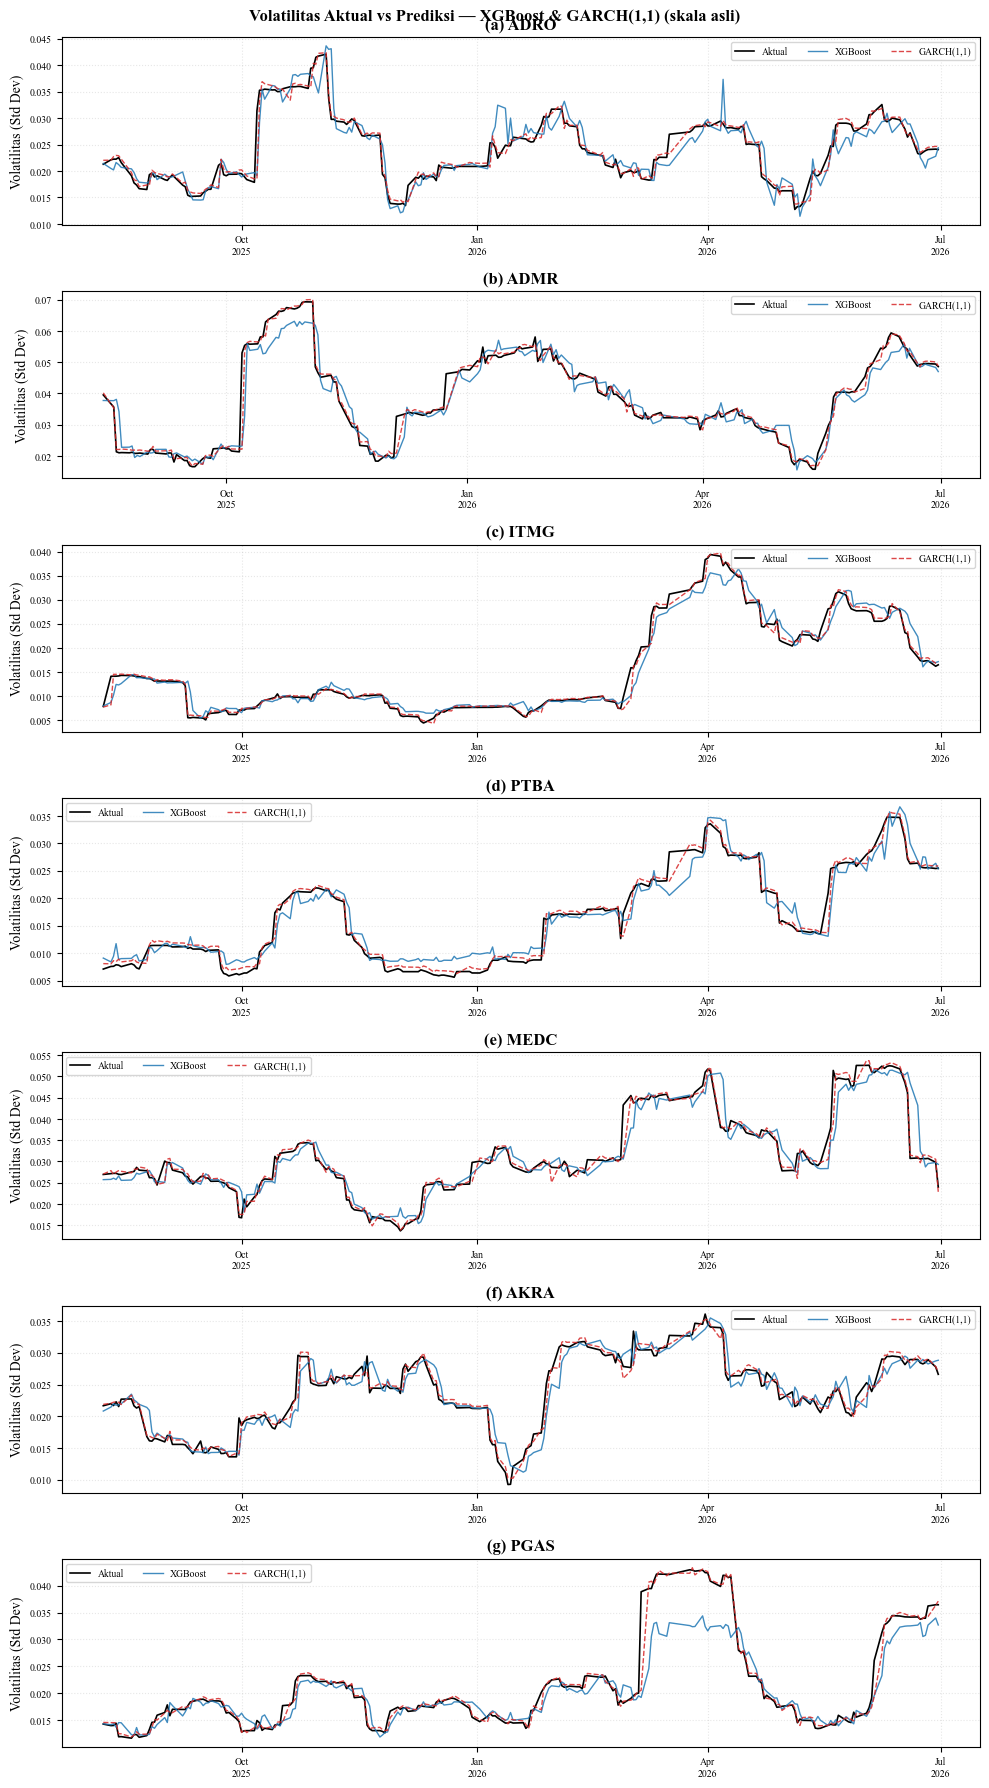

In [11]:
import string, matplotlib.dates as mdates
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 10})

fig, axes = plt.subplots(len(URUTAN_EMITEN), 1, figsize=(10, 2.6 * len(URUTAN_EMITEN)))
for i, (ax, e) in enumerate(zip(np.atleast_1d(axes), URUTAN_EMITEN)):
    g = gabung[gabung['Emiten'] == e].sort_values('Date')
    ax.plot(g['Date'], g['Y_Aktual'], color='black', lw=1.2, label='Aktual')
    ax.plot(g['Date'], g['XGBoost'], color='#1f77b4', lw=1.0, alpha=.85, label='XGBoost')
    ax.plot(g['Date'], g['GARCH'], color='#d62728', lw=1.0, ls='--', alpha=.85, label='GARCH(1,1)')
    ax.set_title(f'({string.ascii_lowercase[i]}) {e}', fontweight='bold')
    ax.set_ylabel('Volatilitas (Std Dev)')
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.tick_params(labelsize=7); ax.legend(fontsize=7, ncol=3); ax.grid(True, alpha=.3, ls=':')
plt.suptitle('Volatilitas Aktual vs Prediksi — XGBoost & GARCH(1,1) (skala asli)', fontweight='bold')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_prediksi_garch_vs_xgboost.png', dpi=300, bbox_inches='tight')
plt.show()

## 💾 CELL 11 — Simpan Hasil Prediksi

In [12]:
df_all = pd.concat(dict_hasil_garch.values(), ignore_index=True)
df_all.to_csv(DIR_TABEL / 'hasil_prediksi_garch.csv', encoding='utf-8-sig', index=False)
print('='*70); print('✅ BASELINE GARCH(1,1) SELESAI')
for f in ['hasil_prediksi_garch.csv', 'tabel_parameter_garch.csv',
          'tabel_evaluasi_garch_vs_model.csv', 'tabel_uji_dm_garch.csv']:
    print(f'  💾 {DIR_TABEL.name}/{f}')
print(f'  🖼️ {DIR_GAMBAR.name}/gambar_prediksi_garch_vs_xgboost.png')
print('='*70)

✅ BASELINE GARCH(1,1) SELESAI
  💾 tabel/hasil_prediksi_garch.csv
  💾 tabel/tabel_parameter_garch.csv
  💾 tabel/tabel_evaluasi_garch_vs_model.csv
  💾 tabel/tabel_uji_dm_garch.csv
  🖼️ model/gambar_prediksi_garch_vs_xgboost.png


In [ ]:
# ── DIAGNOSTIK: baseline naive & definisi Vol_Lag1 ──
gab_full = pd.read_csv(F_GABUNGAN)
gab_full = gab_full.rename(columns={K_TGL: 'Date', K_EMT: 'Emiten'})
gab_full['Date'] = pd.to_datetime(gab_full['Date']).dt.normalize()

rows = []
for e in URUTAN_EMITEN:
    d = dict_data[e]
    g = gabung[gabung['Emiten'] == e]
    vol_t = d['target'].shift(1)              s       # sigma hari t (diketahui di t)
    naive = vol_t.loc[g['Date']].values
    m = evaluasi_semua_metrik(g['Y_Aktual'], naive)

    # Vol_Lag1 = sigma_t atau sigma_{t-1}?
    f = gab_full[gab_full['Emiten'] == e].set_index('Date')
    c = f.index.intersection(d.index)
    beda_t   = (f.loc[c, 'Vol_Lag1'] - vol_t.loc[c]).abs().median()
    beda_tm1 = (f.loc[c, 'Vol_Lag1'] - d['target'].shift(2).loc[c]).abs().median()
    rows.append({'Emiten': e, 'Naive RMSE(1e-3)': round(m['RMSE']*1e3, 3),
                 'Naive MAPE': m['MAPE (%)'], 'Naive R2': m['R2'],
                 'Vol_Lag1 = ': 'sigma_t' if beda_t < beda_tm1 else 'sigma_{t-1}'})
print(pd.DataFrame(rows).to_string(index=False))

Emiten  Naive RMSE(1e-3)  Naive MAPE  Naive R2 Vol_Lag1 = 
  ADRO             1.858        4.18    0.9131 sigma_{t-1}
  ADMR             3.615        4.81    0.9368 sigma_{t-1}
  ITMG             1.357        4.85    0.9794 sigma_{t-1}
  PTBA             1.556        4.75    0.9653 sigma_{t-1}
  MEDC             2.476        4.07    0.9346 sigma_{t-1}
  AKRA             1.587        4.25    0.9232 sigma_{t-1}
  PGAS             1.988        4.21    0.9452 sigma_{t-1}
